# Here we implement subgraph in two different ways.

### Problem statement
![subgraph](./images/subgraph1.png)

Our task is to build an application that generate an answer of a user query and then translate it into hindi.

I will build this using two different ways of subgraph representations. 

- invoking a graph from a node

- add a graph as a node

## First method

![subgraph 1](./images/subgraph2.png)

In [21]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv

In [22]:
load_dotenv()

True

In [23]:
# subgraph state
class substate(TypedDict):
    input_text : str
    translate_text : str

In [24]:
subgraph_llm = ChatOpenAI(model = "gpt-4o")

In [25]:
def translate_text(state: substate):
    prompt = f"""
Translate the follwoing text to Hindi.
Keep it natural and clear. Do not add extra content.
Text : 
{state["input_text"]}""".strip()

    translated_text = subgraph_llm.invoke(prompt).content

    return {'translate_text': translated_text}

In [26]:
subgraph_builder = StateGraph(substate)
subgraph_builder.add_node("translate_text", translate_text)

subgraph_builder.add_edge(START, "translate_text")
subgraph_builder.add_edge("translate_text", END)

subgraph = subgraph_builder.compile()

In [27]:
class parentstate(TypedDict):

    question: str
    answer_eng: str
    answer_hin: str


In [28]:
parent_llm = ChatOpenAI(model = "gpt-4o")

In [29]:
def generate_answer(state:parentstate):

    prompt = f"""
Generate answer to this query : {state["question"]}""".strip()
    answer = parent_llm.invoke(prompt).content

    return {'answer_eng': answer}

def hindi_transtale(state:parentstate):
    result = subgraph.invoke({'input_text':state['answer_eng']})
    return {'answer_hin':result['translate_text']}

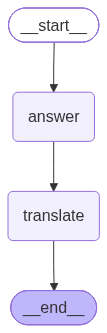

In [30]:
parent_builder = StateGraph(parentstate)
parent_builder.add_node("answer", generate_answer)
parent_builder.add_node("translate", hindi_transtale)

parent_builder.add_edge(START, "answer")
parent_builder.add_edge("answer", "translate")
parent_builder.add_edge('translate', END)

graph = parent_builder.compile()
graph

In [31]:
graph.invoke({'question':"What is gravity?"})

{'question': 'What is gravity?',
 'answer_eng': "Gravity is a fundamental force of nature that attracts two bodies toward each other. While it's most commonly associated with the attraction between objects with mass, such as Earth pulling an apple toward it, it actually applies to all particles that have mass. The strength of this attraction is proportional to the mass of the objects and inversely proportional to the square of the distance between their centers, as described by Isaac Newton's law of universal gravitation. Albert Einstein later provided a more comprehensive explanation with his theory of general relativity, which describes gravity not as a force, but as a curvature of spacetime caused by mass. This means massive objects, like planets or stars, warp the fabric of spacetime, and this curvature affects the motion of other objects. Gravity is essential for many phenomena in the universe, from the orbits of planets and moons to the formation of galaxies and the behavior of l

## 2nd method


In [32]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv

In [33]:
load_dotenv()

True

In [34]:
class ParentState(TypedDict):

    question: str
    answer_eng: str
    answer_hin: str

In [35]:
parent_llm = ChatOpenAI(model='gpt-4o-mini')
subgraph_llm = ChatOpenAI(model='gpt-4o')

In [36]:
def translate_text(state: ParentState):

    prompt = f"""
Translate the following text to Hindi.
Keep it natural and clear. Do not add extra content.

Text:
{state["answer_eng"]}
""".strip()
    
    translated_text = subgraph_llm.invoke(prompt).content

    return {'answer_hin': translated_text}

In [37]:
subgraph_builder = StateGraph(ParentState)

subgraph_builder.add_node('translate_text', translate_text)

subgraph_builder.add_edge(START, 'translate_text')
subgraph_builder.add_edge('translate_text', END)

subgraph = subgraph_builder.compile()

In [38]:
def generate_answer(state: ParentState):

    answer = parent_llm.invoke(f"You are a helpful assistant. Answer clearly.\n\nQuestion: {state['question']}").content
    return {'answer_eng': answer}

In [42]:
parent_builder = StateGraph(ParentState)

parent_builder.add_node("answer", generate_answer)
parent_builder.add_node("translate", subgraph) # main change is here. subgraph as a node

parent_builder.add_edge(START, 'answer')
parent_builder.add_edge('answer', 'translate')
parent_builder.add_edge('translate', END)

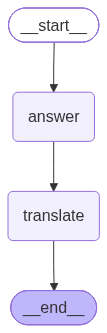

In [40]:
graph = parent_builder.compile()

graph

In [41]:
graph.invoke({'question': 'What is quantum physics'})

{'question': 'What is quantum physics',
 'answer_eng': 'Quantum physics, or quantum mechanics, is a fundamental branch of physics that deals with the behavior of matter and energy at the smallest scales, such as atoms and subatomic particles. It describes the physical properties of nature at the scale of molecules, atoms, and elementary particles.\n\nKey principles of quantum physics include:\n\n1. **Wave-Particle Duality**: Particles, such as electrons and photons, exhibit both particle-like and wave-like behavior depending on how they are observed.\n\n2. **Quantization**: Energy, momentum, and other quantities are not continuous but exist in discrete amounts or "quanta." For example, electrons in an atom exist in specific energy levels.\n\n3. **Uncertainty Principle**: Formulated by Werner Heisenberg, it states that certain pairs of physical properties (like position and momentum) cannot both be known to arbitrary precision at the same time.\n\n4. **Superposition**: Particles can exi